In [1]:
import pandas as pd

data = pd.read_excel('Country Data.xlsx')
# data.head()

In [2]:
data.isnull().sum()

Country                              0
Year                                 0
Status                               0
Life expectancy                     10
Adult Mortality                     10
infant deaths                        0
Alcohol                            194
percentage expenditure               0
Hepatitis B                        553
Measles                              0
BMI                                 34
under-five deaths                    0
Polio                               19
Total expenditure                  226
Diphtheria                          19
HIV/AIDS                             0
GDP                                448
Population                         652
thinness  1-19 years                34
thinness 5-9 years                  34
Income composition of resources    167
Schooling                          163
dtype: int64

In [3]:
data.shape

(2938, 22)

In [4]:
data['Class Status'] = data['Status'].map({'Developing': 0, 'Developed': 1})

In [5]:
data.drop('Status', axis=1, inplace=True)

In [6]:
print((data['Class Status'] == 0).sum())
print((data['Class Status'] == 1).sum())

2426
512


In [7]:
data.shape

(2938, 22)

In [8]:
data.columns

Index(['Country', 'Year', 'Life expectancy', 'Adult Mortality',
       'infant deaths', 'Alcohol', 'percentage expenditure', 'Hepatitis B',
       'Measles', 'BMI', 'under-five deaths', 'Polio', 'Total expenditure',
       'Diphtheria', 'HIV/AIDS', 'GDP', 'Population', 'thinness  1-19 years',
       'thinness 5-9 years', 'Income composition of resources', 'Schooling',
       'Class Status'],
      dtype='object')

In [9]:
data.describe()

,Year,Life expectancy,Adult Mortality,infant deaths,Alcohol,percentage expenditure,Hepatitis B,Measles,BMI,under-five deaths,...,Total expenditure,Diphtheria,HIV/AIDS,GDP,Population,thinness 1-19 years,thinness 5-9 years,Income composition of resources,Schooling,Class Status
count,2938.000000,2928.000000,2928.000000,2938.000000,2744.000000,2938.000000,2385.000000,2938.000000,2904.000000,2938.000000,...,2712.00000,2919.000000,2938.000000,2490.000000,2.286000e+03,2904.000000,2904.000000,2771.000000,2775.000000,2938.000000
mean,2007.518720,69.224932,164.796448,30.303948,4.602861,738.251295,80.940461,2419.592240,38.321247,42.035739,...,5.93819,82.324084,1.742103,7483.158469,1.275338e+07,4.839704,4.870317,0.627551,11.992793,0.174268
std,4.613841,9.523867,124.292079,117.926501,4.052413,1987.914858,25.070016,11467.272489,20.044034,160.445548,...,2.49832,23.716912,5.077785,14270.169342,6.101210e+07,4.420195,4.508882,0.210904,3.358920,0.379405
min,2000.000000,36.300000,1.000000,0.000000,0.010000,0.000000,1.000000,0.000000,1.000000,0.000000,...,0.37000,2.000000,0.100000,1.681350,3.400000e+01,0.100000,0.100000,0.000000,0.000000,0.000000
25%,2004.000000,63.100000,74.000000,0.000000,0.877500,4.685343,77.000000,0.000000,19.300000,0.000000,...,4.26000,78.000000,0.100000,463.935626,1.957932e+05,1.600000,1.500000,0.493000,10.100000,0.000000
50%,2008.000000,72.100000,144.000000,3.000000,3.755000,64.912906,92.000000,17.000000,43.500000,4.000000,...,5.75500,93.000000,0.100000,1766.947595,1.386542e+06,3.300000,3.300000,0.677000,12.300000,0.000000
75%,2012.000000,75.700000,228.000000,22.000000,7.702500,441.534144,97.000000,360.250000,56.200000,28.000000,...,7.49250,97.000000,0.800000,5910.806335,7.420359e+06,7.200000,7.200000,0.779000,14.300000,0.000000
max,2015.000000,89.000000,723.000000,1800.000000,17.870000,19479.911610,99.000000,212183.000000,87.300000,2500.000000,...,17.60000,99.000000,50.600000,119172.741800,1.293859e+09,27.700000,28.600000,0.948000,20.700000,1.000000


In [10]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2938 entries, 0 to 2937
Data columns (total 22 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   Country                          2938 non-null   object 
 1   Year                             2938 non-null   int64  
 2   Life expectancy                  2928 non-null   float64
 3   Adult Mortality                  2928 non-null   float64
 4   infant deaths                    2938 non-null   int64  
 5   Alcohol                          2744 non-null   float64
 6   percentage expenditure           2938 non-null   float64
 7   Hepatitis B                      2385 non-null   float64
 8   Measles                          2938 non-null   int64  
 9   BMI                              2904 non-null   float64
 10  under-five deaths                2938 non-null   int64  
 11  Polio                            2919 non-null   float64
 12  Total expenditure   

In [11]:
x = data.drop(['Country', 'Year', 'Class Status'], axis=1)
y = data['Class Status']

In [12]:
from sklearn.model_selection import train_test_split

x_train, x_test, y_train, y_test = train_test_split(x, y, random_state=42, test_size=0.3, stratify=y)

In [13]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline

from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.metrics import f1_score, classification_report

from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (
    RandomForestClassifier,
    GradientBoostingClassifier,
    AdaBoostClassifier,
    ExtraTreesClassifier
)
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB
from xgboost import XGBClassifier

In [20]:
models = {
    'Logistic Regression': LogisticRegression(),
    'Gaussian NB': GaussianNB(),
    'SVC': SVC(),
    'KNN': KNeighborsClassifier(),
    'Decision Tree': DecisionTreeClassifier(),
    'Random Forest': RandomForestClassifier(),
    'Extra Trees': ExtraTreesClassifier(),
    'AdaBoost': AdaBoostClassifier(),
    'Gradient Boosting': GradientBoostingClassifier(),
    'XGBoost': XGBClassifier(),
}

results = []

skf = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

for name, model in models.items():
    pipeline = ImbPipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler()),
        ('smote', SMOTE()),
        ('model', model)
    ])

    grid = GridSearchCV(
        estimator=pipeline,
        param_grid={},
        cv=skf,
        scoring='f1_macro',
        n_jobs=-1
    )

    grid.fit(x_train, y_train)
    y_pred = grid.predict(x_test)

    report = classification_report(
        y_test,
        y_pred,
        output_dict=True,
        labels=[0, 1],
        zero_division=0
    )

    results.append({
        'Model': name,
        'Accuracy': report['accuracy'],
        'Precision_0': report['0']['precision'],
        'Recall_0': report['0']['recall'],
        'F1_0': report['0']['f1-score'],
        'Precision_1': report['1']['precision'],
        'Recall_1': report['1']['recall'],
        'F1_1': report['1']['f1-score'],
        'F1_Macro': report['macro avg']['f1-score'],
    })

    results_df = pd.DataFrame(results)
    results_df = results_df.sort_values(by='F1_Macro', ascending=False).reset_index(drop=True)

results_df
    

,Model,Accuracy,Precision_0,Recall_0,F1_0,Precision_1,Recall_1,F1_1,F1_Macro
0,Extra Trees,0.984127,0.991736,0.989011,0.990371,0.948718,0.961039,0.954839,0.972605
1,Random Forest,0.982993,0.993084,0.986264,0.989662,0.937107,0.967532,0.952077,0.970869
2,XGBoost,0.982993,0.991724,0.987637,0.989677,0.942675,0.961039,0.951768,0.970723
3,Gradient Boosting,0.968254,0.988827,0.972527,0.980609,0.879518,0.948052,0.912500,0.946555
4,Decision Tree,0.958050,0.973937,0.975275,0.974605,0.882353,0.876623,0.879479,0.927042
5,KNN,0.952381,0.977716,0.964286,0.970954,0.841463,0.896104,0.867925,0.919439
6,AdaBoost,0.937642,0.984173,0.939560,0.961349,0.764706,0.928571,0.838710,0.900029
7,SVC,0.927438,0.986804,0.924451,0.954610,0.725000,0.941558,0.819209,0.886909
8,Logistic Regression,0.916100,0.975291,0.921703,0.947740,0.706186,0.889610,0.787356,0.867548
9,Gaussian NB,0.811791,0.991259,0.778846,0.872308,0.480645,0.967532,0.642241,0.757275


<div style="padding:25px; border-radius:12px; radius:2px solid #ddd;">

<h1 style="text-align:center;">Análise Visual</h1>
    
</div>

<div style="padding:25px; border-radius:12px; radius:2px solid #ddd";>

<h1 style="text-align:center; color:gray">Acurácia</h1>

<p style="text-align:center; font-size:18px;">Gráfico de barras</p>
    
</div>

In [22]:
import seaborn as sns
import matplotlib.pyplot as plt

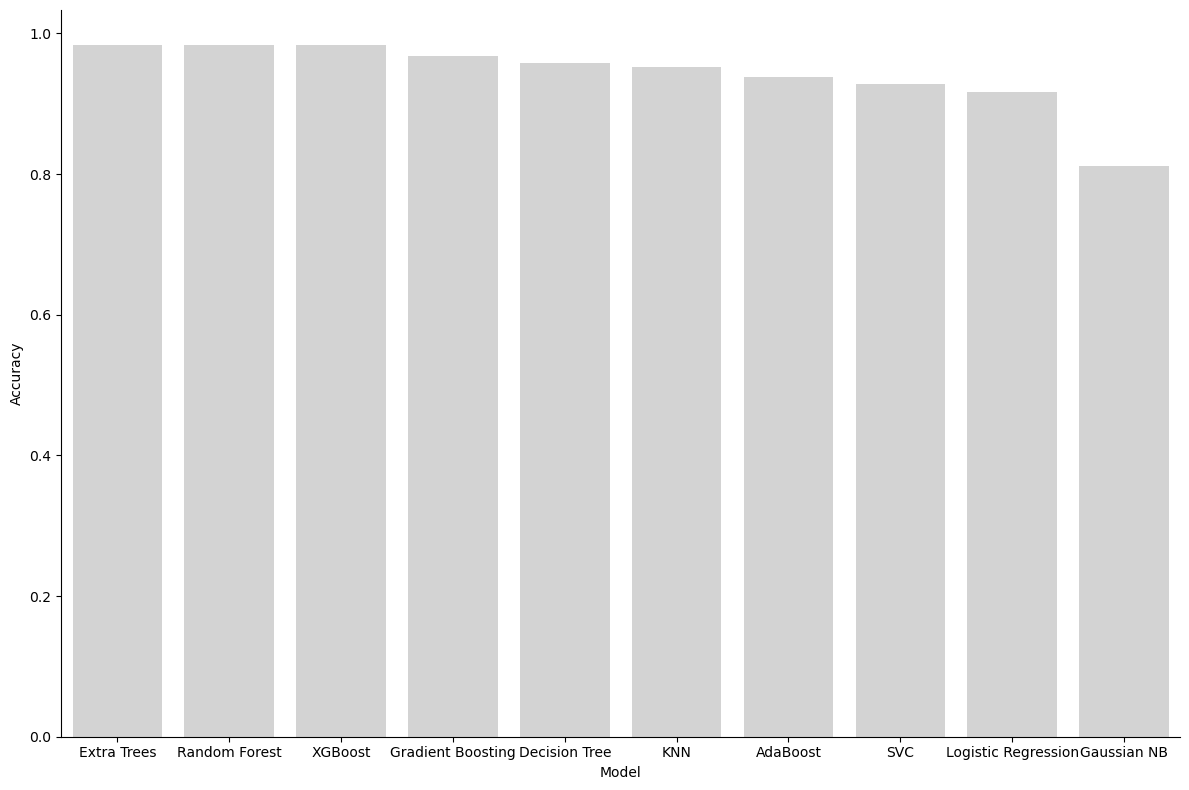

In [39]:
plt.figure(figsize=(12, 8))

order = results_df.sort_values(by='Accuracy', ascending=False)['Model']

sns.barplot(
            data=results_df, 
            x='Model', 
            y='Accuracy',
            color='lightgrey',
            order=order
           )

ax = plt.gca()

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.xlabel('Model')
plt.ylabel('Accuracy')

plt.tight_layout()
plt.show()

<div style="padding:25px; border-radius:18px; radius:2px solid #ddd";>

<h1 style="text-align:center; color:lightgreen">Precisão Classe 0 (Development)</h1>

<p style="text-align:center; font-size:15px;">Gráfico de barras</p>
    
</div>

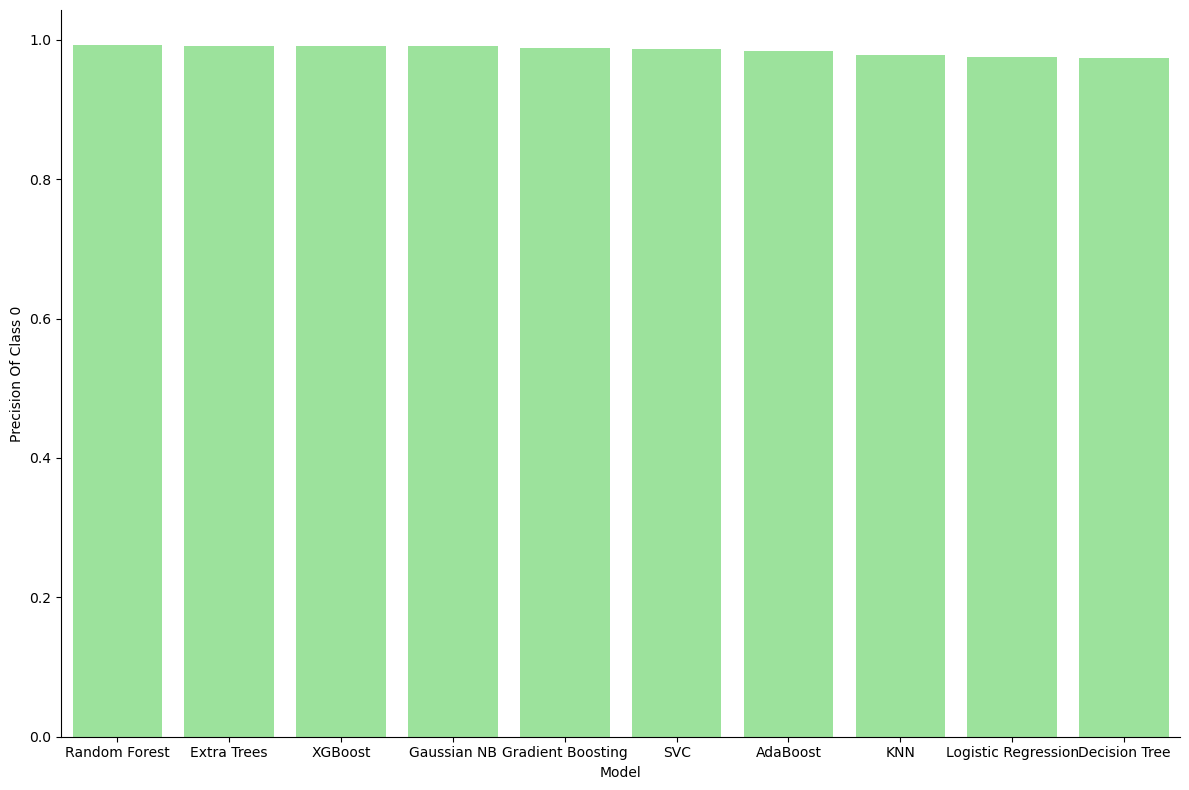

In [38]:
plt.figure(figsize=(12, 8))

order = results_df.sort_values(by='Precision_0', ascending=False)['Model']

sns.barplot(
            data=results_df, 
            x='Model', 
            y='Precision_0',
            color='lightgreen',
            order=order
           )

ax = plt.gca()

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.xlabel('Model')
plt.ylabel('Precision Of Class 0')

plt.tight_layout()
plt.show()

<div style="padding:25px; border-radius:18px; radius:2px solid #ddd;">

<h1 style="text-align:center; color:darkgreen";>Precisão Classe 1 (Developed)</h1>

<p style="text-align:center; font-size:15px";>Gráfico de barras</p>
    
</div>

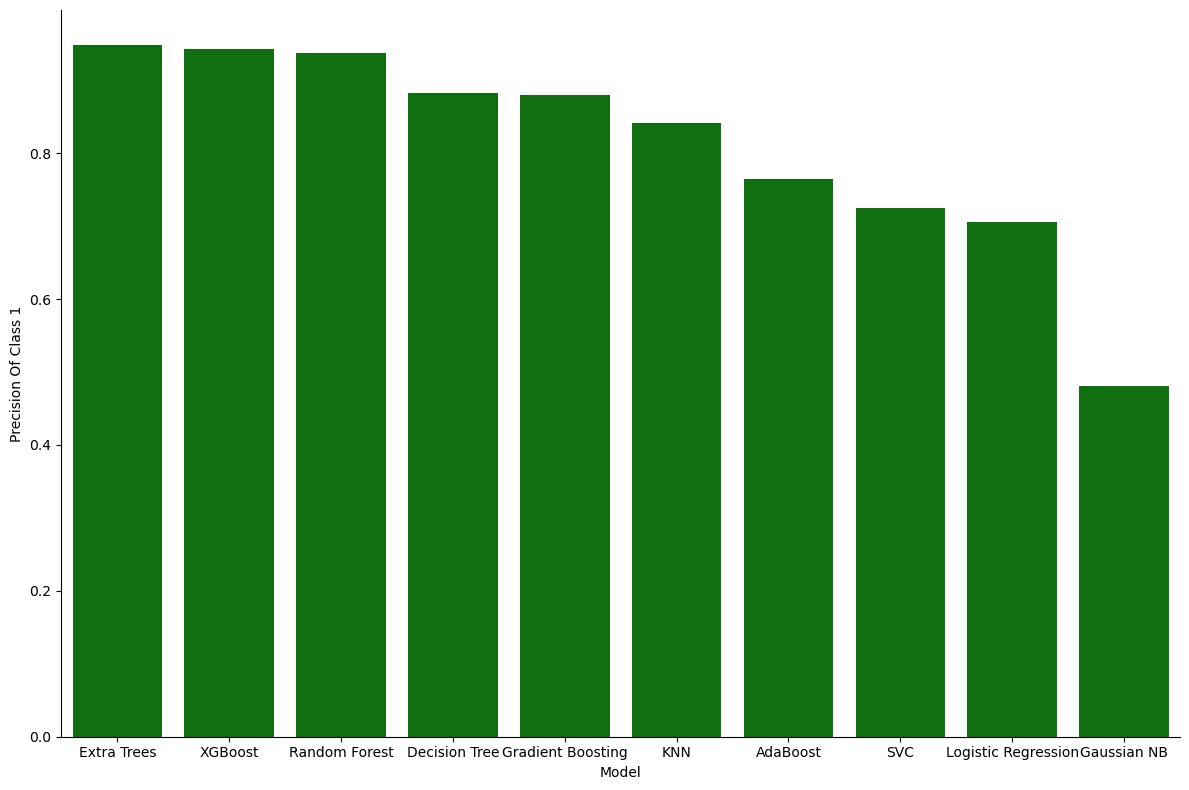

In [37]:
plt.figure(figsize=(12, 8))

order = results_df.sort_values(by='Precision_1', ascending=False)['Model']

sns.barplot(
            data=results_df, 
            x='Model', 
            y='Precision_1',
            color='green',
            order=order
           )

ax = plt.gca()

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.xlabel('Model')
plt.ylabel('Precision Of Class 1')

plt.tight_layout()
plt.show()

<div style='padding:25px, border-radius:18px, radius:2px solid #ddd';>

<h1 style='text-align:center; color:lightblue';>Recall Classe 0 (Development)</h1>

<p style='text-align:center; font-size:15px';>Gráfico de barras</p>
    
</div>

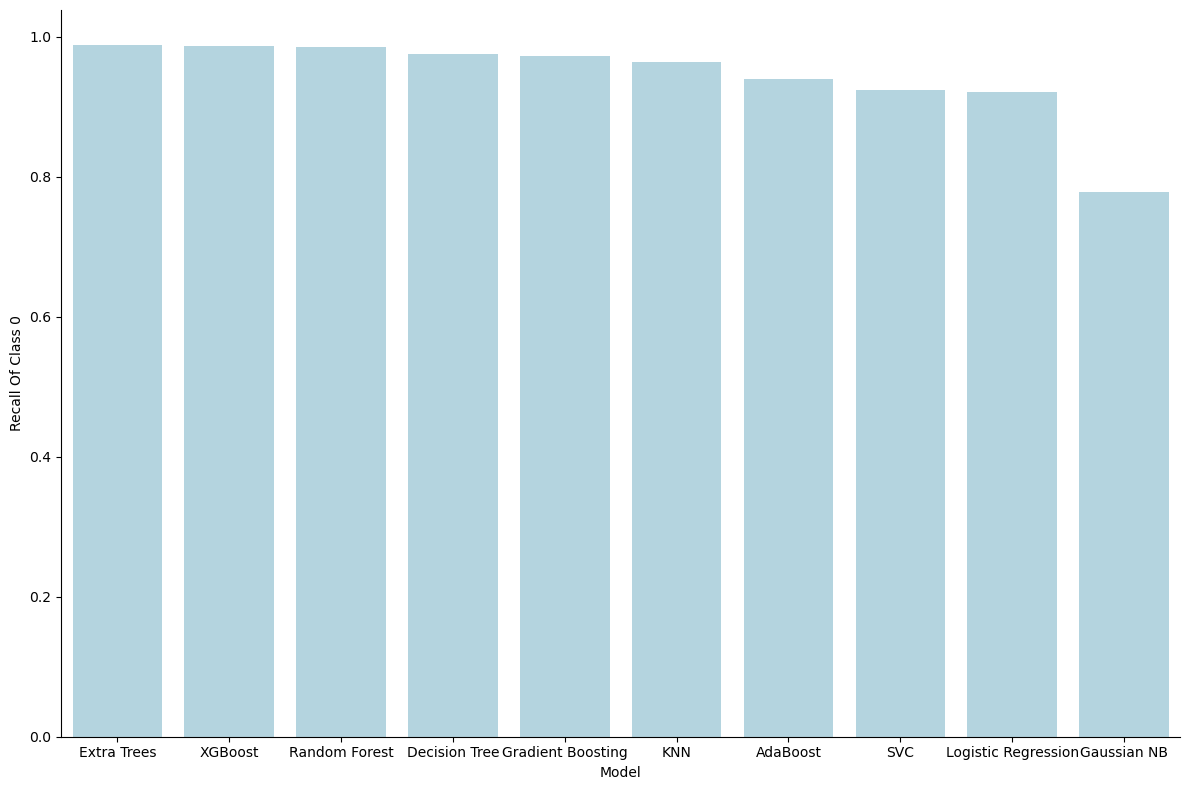

In [36]:
plt.figure(figsize=(12, 8))

order = results_df.sort_values(by='Recall_0', ascending=False)['Model']

sns.barplot(
            data=results_df, 
            x='Model', 
            y='Recall_0',
            color='lightblue',
            order=order
           )

ax = plt.gca()

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.xlabel('Model')
plt.ylabel('Recall Of Class 0')

plt.tight_layout()
plt.show()

<div style='padding:25px, border-radius:18px, radius:2px solid #ddd';>

<h1 style='text-align:center; color:blue';>Recall Classe 1 (Developed)</h1>

<p style='text-align:center; font-size:15px';>Gráfico de barras</p>
    
</div>

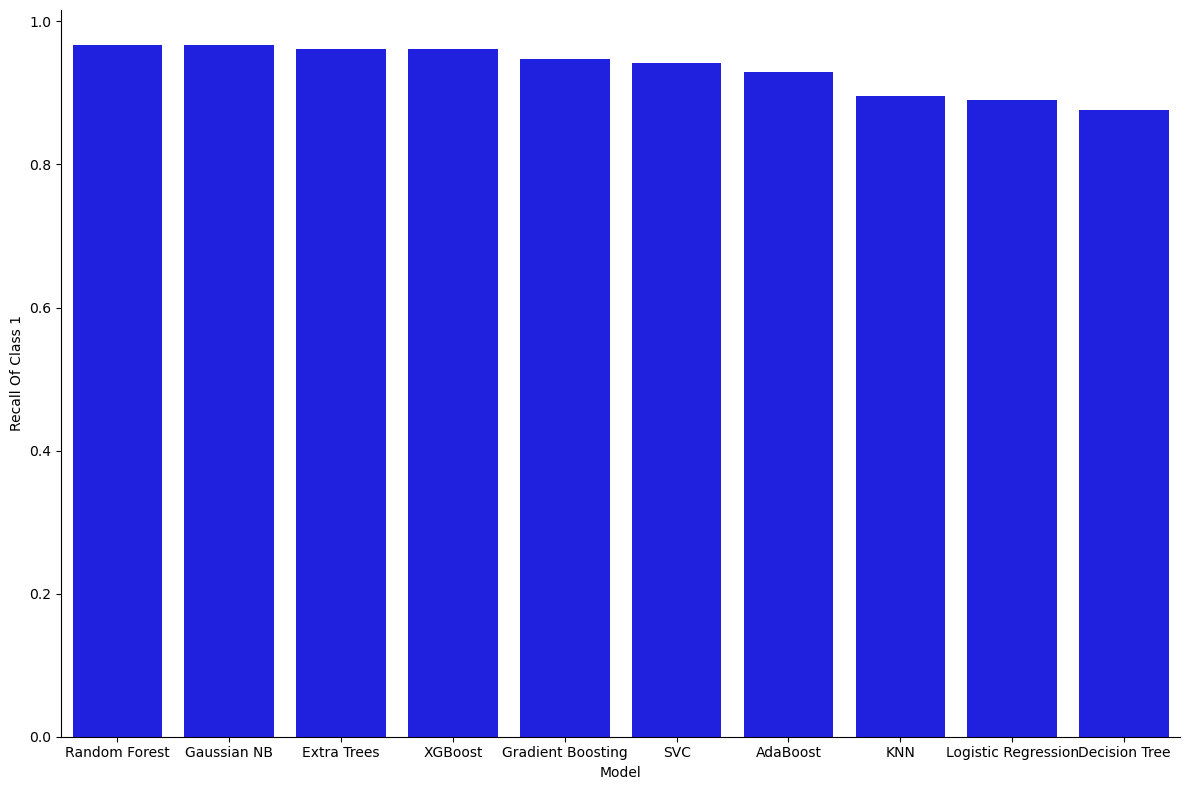

In [40]:
plt.figure(figsize=(12, 8))

order = results_df.sort_values(by='Recall_1', ascending=False)['Model']

sns.barplot(
            data=results_df, 
            x='Model', 
            y='Recall_1',
            color='blue',
            order=order
           )

ax = plt.gca()

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.xlabel('Model')
plt.ylabel('Recall Of Class 1')

plt.tight_layout()
plt.show()

<div style='padding:25px, border-radius:18px, radius:2px solid #ddd';>

<h1 style='text-align:center; color:orange';>F1-score Classe 0 (Development)</h1>

<p style='text-align:center; font-size:15px';>Gráfico de barras</p>
    
</div>

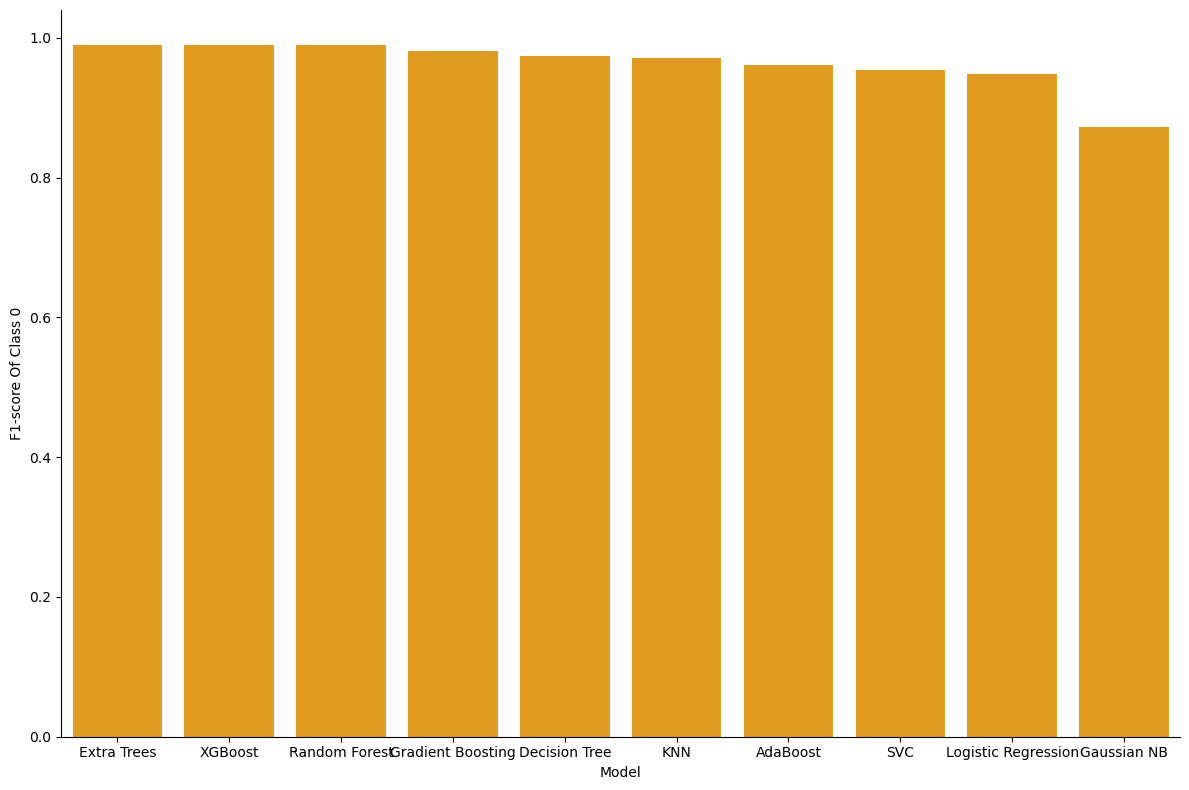

In [41]:
plt.figure(figsize=(12, 8))

order = results_df.sort_values(by='F1_0', ascending=False)['Model']

sns.barplot(
            data=results_df, 
            x='Model', 
            y='F1_0',
            color='orange',
            order=order
           )

ax = plt.gca()

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.xlabel('Model')
plt.ylabel('F1-score Of Class 0')

plt.tight_layout()
plt.show()

<div style='padding:25px, border-radius:18px, radius:2px solid #ddd';>

<h1 style='text-align:center; color:brown';>F1-score Classe 1 (Developed)</h1>

<p style='text-align:center; font-size:15px';>Gráfico de barras</p>
    
</div>

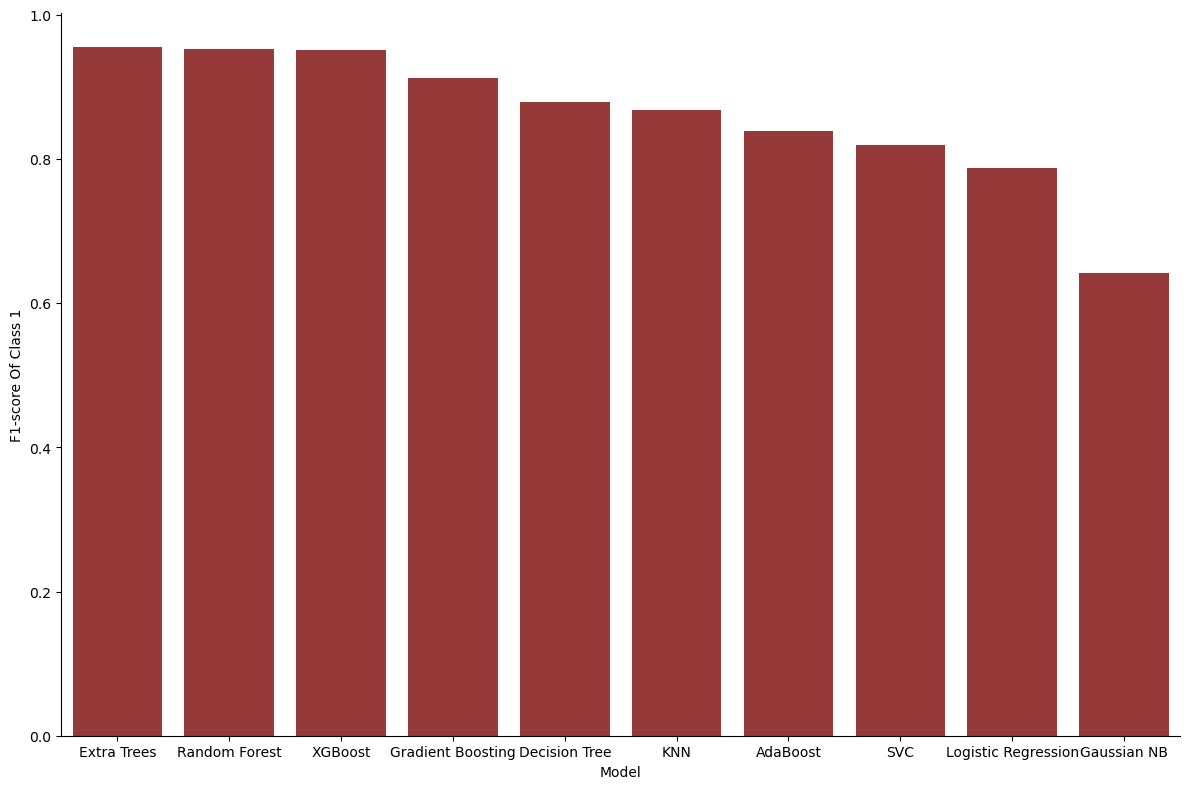

In [42]:
plt.figure(figsize=(12, 8))

order = results_df.sort_values(by='F1_1', ascending=False)['Model']

sns.barplot(
            data=results_df, 
            x='Model', 
            y='F1_1',
            color='brown',
            order=order
           )

ax = plt.gca()

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.xlabel('Model')
plt.ylabel('F1-score Of Class 1')

plt.tight_layout()
plt.show()

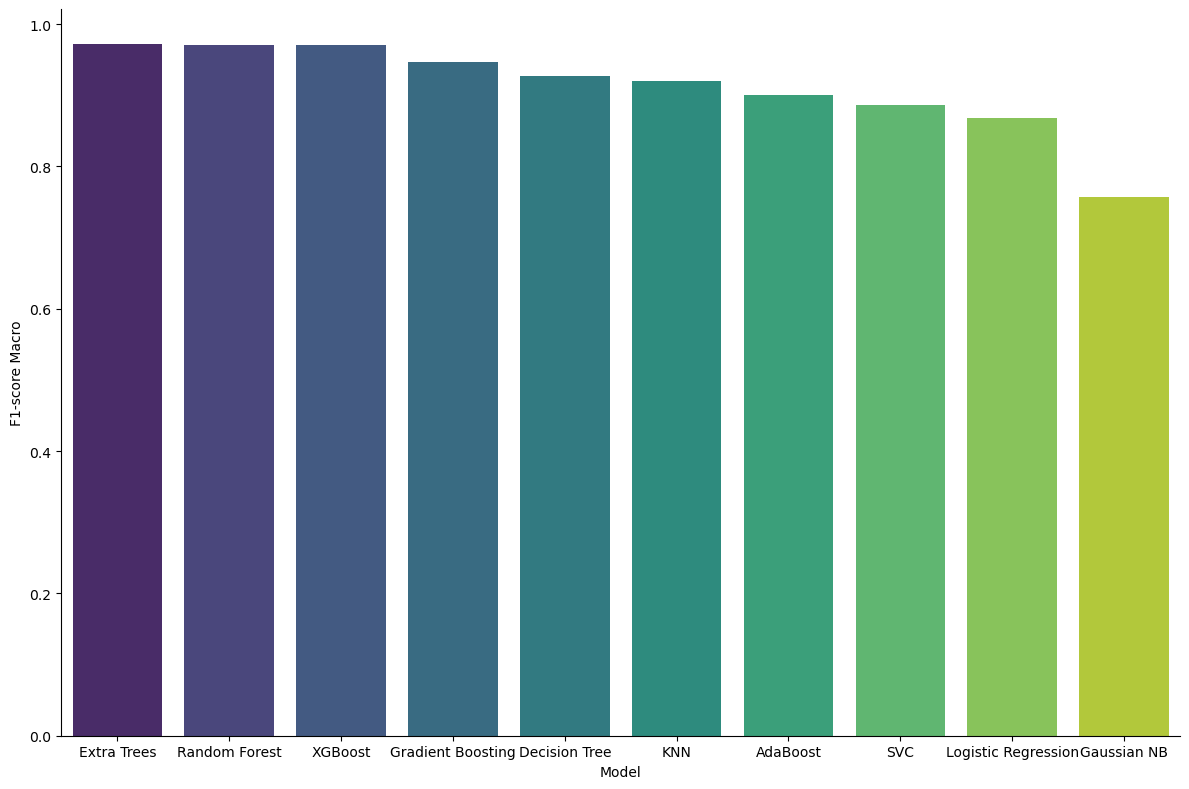

In [48]:
plt.figure(figsize=(12, 8))

order = results_df.sort_values(by='F1_Macro', ascending=False)['Model']

sns.barplot(
            data=results_df, 
            x='Model', 
            y='F1_Macro',
            hue='Model',
            palette='viridis',
            legend=False,
            order=order
           )

ax = plt.gca()

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.xlabel('Model')
plt.ylabel('F1-score Macro')

plt.tight_layout()
plt.show()